<a href="https://colab.research.google.com/github/Azhar-TKM/AI-ML/blob/main/RandomForest_DecisionTree_SupportVector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Accuracy: 80.45%

Classification Report:
              precision    recall  f1-score   support

Not Survived       0.81      0.87      0.84       105
    Survived       0.79      0.72      0.75        74

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.80      0.80      0.80       179



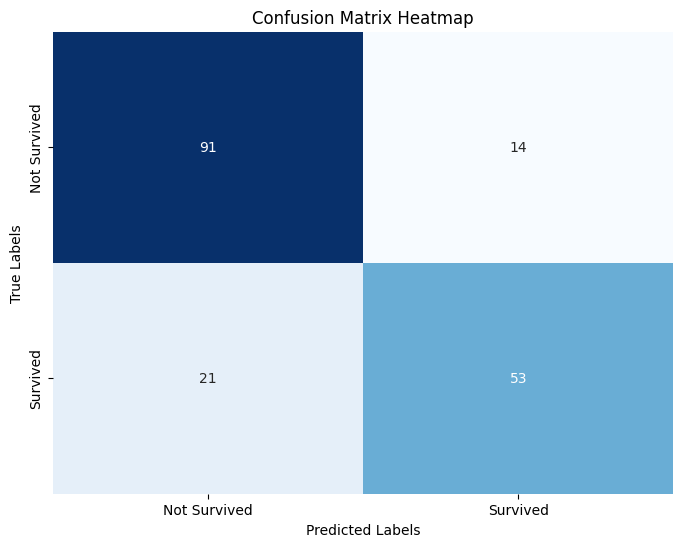

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier

df = pd.read_csv('titanic.csv')

X = df.drop(['Survived', 'Name', 'Ticket', 'Cabin', 'Embarked', 'PassengerId'], axis=1)
X['Sex'] = X['Sex'].map({'male': 0, 'female': 1})
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train = X_train.copy()
X_test = X_test.copy()
X_train['Age'] = X_train['Age'].fillna(X_train['Age'].mean())
X_test['Age'] = X_test['Age'].fillna(X_train['Age'].mean())
X_train['Fare'] = X_train['Fare'].fillna(X_train['Fare'].mean())
X_test['Fare'] = X_test['Fare'].fillna(X_train['Fare'].mean())

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

classifier = RandomForestClassifier(n_estimators=100, random_state=42)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

print('\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=['Not Survived', 'Survived']))

conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False,
            xticklabels=['Not Survived', 'Survived'], yticklabels=['Not Survived', 'Survived'])

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

 Accuracy: 76.54%

Classification Report:
              precision    recall  f1-score   support

Not Survived       0.81      0.79      0.80       105
    Survived       0.71      0.73      0.72        74

    accuracy                           0.77       179
   macro avg       0.76      0.76      0.76       179
weighted avg       0.77      0.77      0.77       179



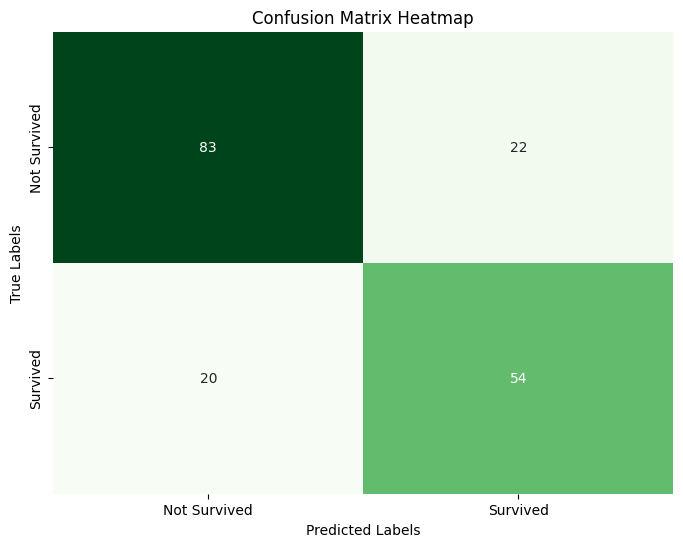

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dtc_classifier = DecisionTreeClassifier(criterion='entropy', random_state=42)
dtc_classifier.fit(X_train, y_train)
y_pred_dtc = dtc_classifier.predict(X_test)

accuracy_dtc = accuracy_score(y_test, y_pred_dtc)
print(f' Accuracy: {accuracy_dtc * 100:.2f}%')

print('\nClassification Report:')
print(classification_report(y_test, y_pred_dtc, target_names=['Not Survived', 'Survived']))

conf_matrix_dtc = confusion_matrix(y_test, y_pred_dtc)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_dtc, annot=True, fmt='g', cmap='Greens', cbar=False,
            xticklabels=['Not Survived', 'Survived'], yticklabels=['Not Survived', 'Survived'])

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

Support Vector Classifier Accuracy: 81.01%

Support Vector Classifier Classification Report:
              precision    recall  f1-score   support

Not Survived       0.81      0.88      0.84       105
    Survived       0.80      0.72      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



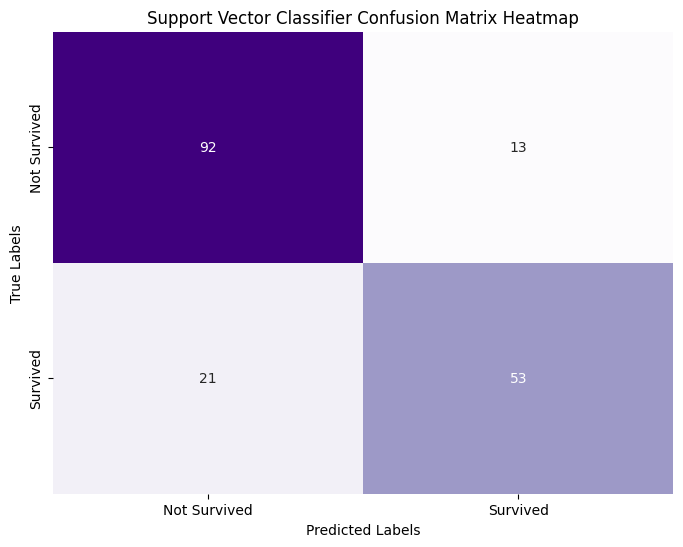

In [ ]:
from sklearn.svm import SVC

svc_classifier = SVC(random_state=42)
svc_classifier.fit(X_train, y_train)
y_pred_svc = svc_classifier.predict(X_test)

accuracy_svc = accuracy_score(y_test, y_pred_svc)
print(f'Support Vector Classifier Accuracy: {accuracy_svc * 100:.2f}%')

print('\nSupport Vector Classifier Classification Report:')
print(classification_report(y_test, y_pred_svc, target_names=['Not Survived', 'Survived']))

conf_matrix_svc = confusion_matrix(y_test, y_pred_svc)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_svc, annot=True, fmt='g', cmap='Purples', cbar=False,
            xticklabels=['Not Survived', 'Survived'], yticklabels=['Not Survived', 'Survived'])

plt.title('Support Vector Classifier Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()